# Superstore Sales & Profit Analysis

## Project Overview
This project analyzes Superstore sales and profitability using Python.

## Objectives
- Analyze sales and profit across product sub-categories.
- Investigate the relationship between discounts and profitability.
- Identify loss-making product categories.
- Present business insights through visualizations.

## Tools Used
Python, Pandas, Matplotlib, Seaborn, Jupyter Notebook.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [7]:
df = pd.read_excel("Store_data.xls")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [8]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape: (9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           

In [9]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
loss_records = (df["Profit"] < 0).sum()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Loss-Making Records: {loss_records:,}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Quantity Sold: 37,873
Loss-Making Records: 1,871



## 3. Category-wise Profit Analysis

This section compares total profit across product categories to identify the strongest and weakest contributors to overall profitability.


In [10]:
category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64

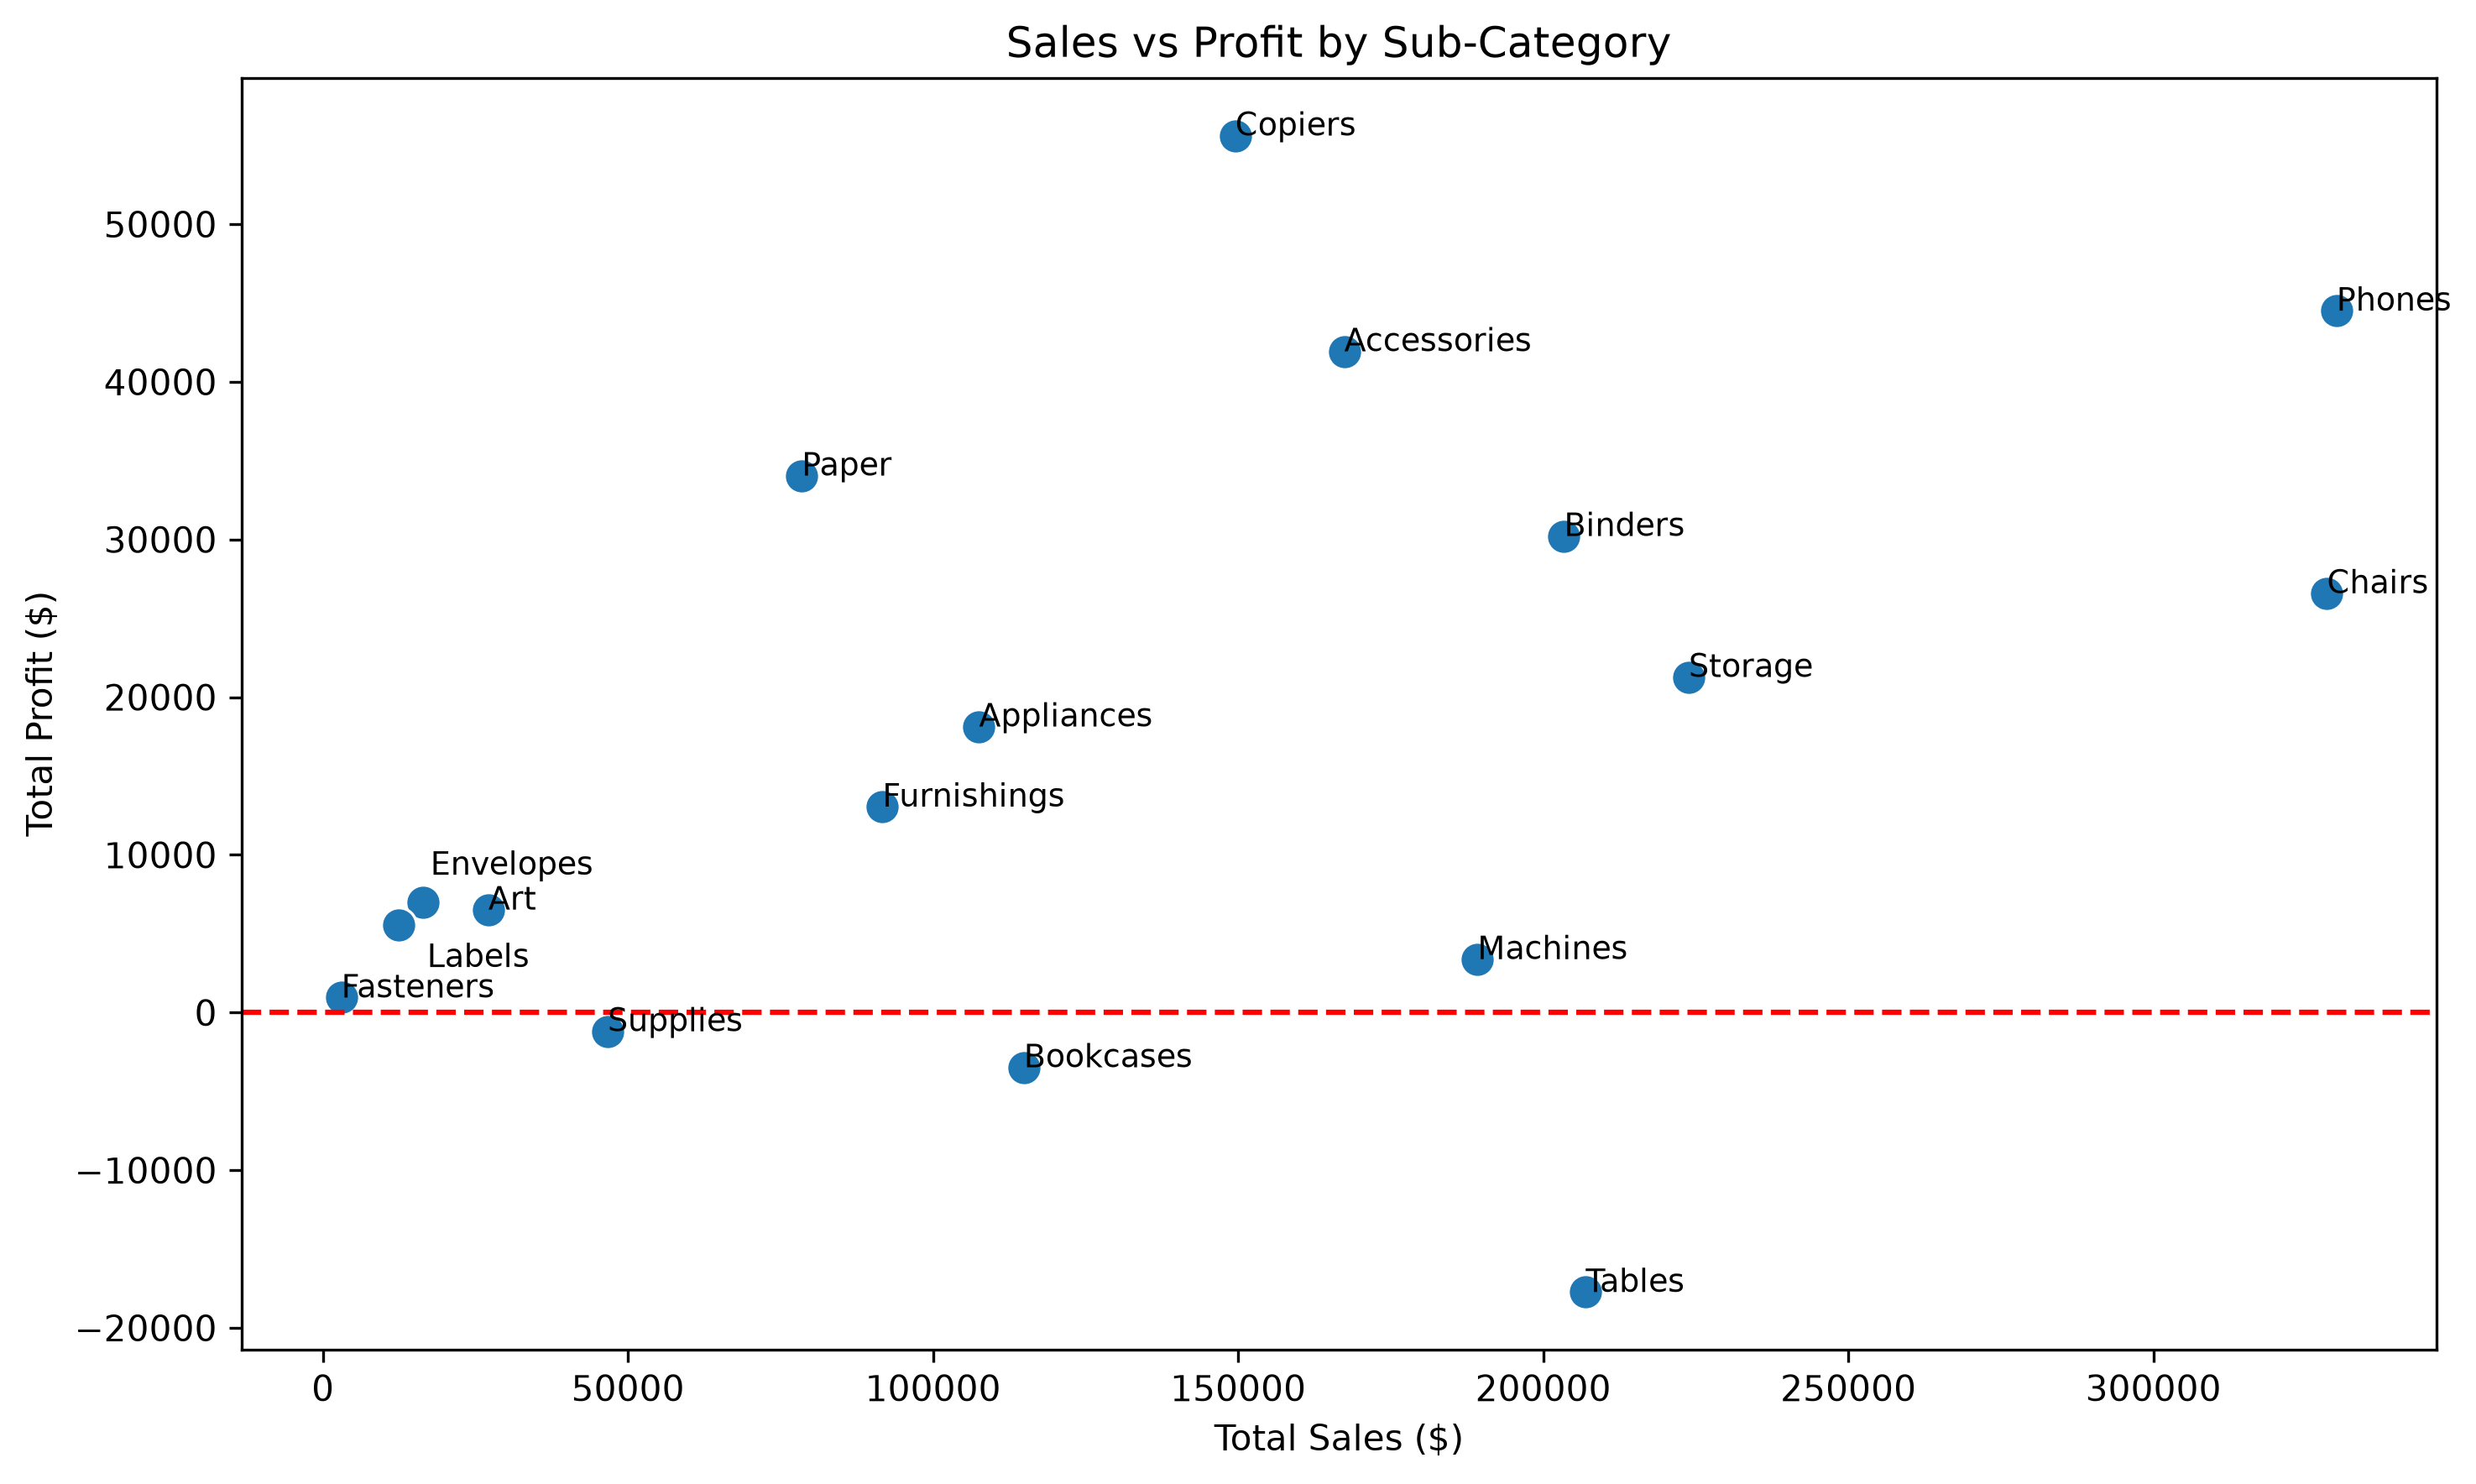

In [11]:
from IPython.display import Image, display

display(Image(filename="Images/sales_vs_profit_subcategory.png"))


**Key Insight:** Technology generates the highest total profit, followed by Office Supplies. Furniture contributes the least profit, highlighting an area for further investigation.


## 4. Sub-Category-wise Profit Analysis

This section compares total profit across product sub-categories to identify the most profitable and loss-making products.

subcat_profit = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

subcat_profit

In [13]:
subcat_profit = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

subcat_profit

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64

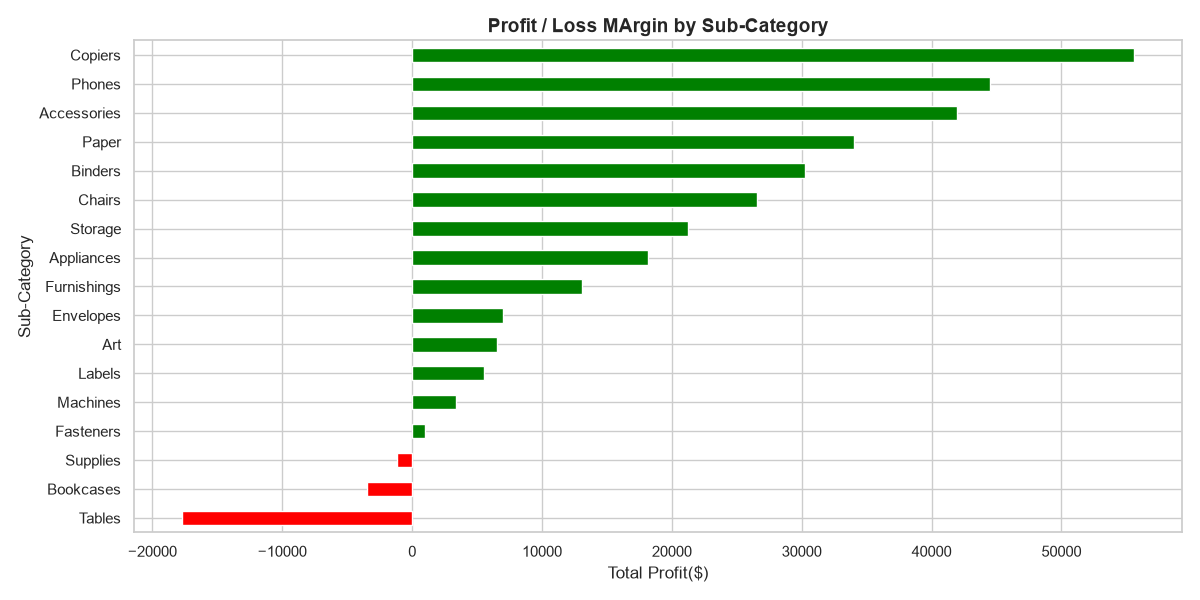

In [14]:
from IPython.display import Image, display

display(Image(filename="Images/subcat_profit_loss.png"))

**Key Insight:** Tables and Bookcases generate negative total profit, despite contributing to overall sales. These sub-categories should be investigated further to understand the factors associated with their losses.

## 5. Discount vs Average Profit Analysis

This section examines the relationship between discount rates and average profit to identify discount levels associated with lower profitability.

In [15]:
discount_profit = (
    df.groupby("Discount")["Profit"]
    .mean()
    .sort_index()
)

discount_profit

Discount
0.00     66.900292
0.10     96.055074
0.15     27.288298
0.20     24.702572
0.30    -45.679636
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -101.796797
Name: Profit, dtype: float64

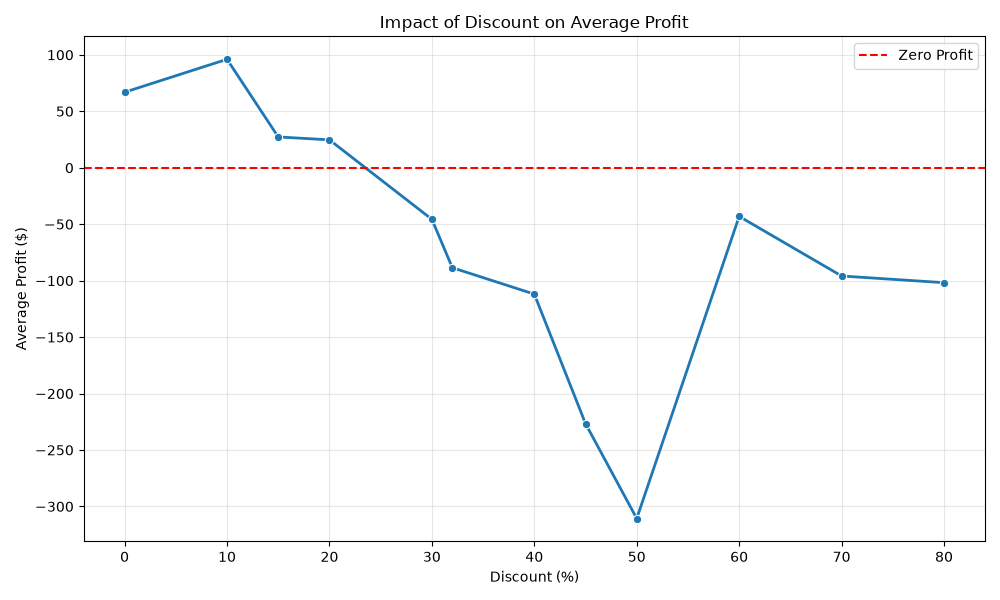

In [16]:
from IPython.display import Image, display

display(Image(filename="Images/Discount_analysis.png"))

**Key Insight:** Higher discount levels are associated with lower average profit in this dataset. The business should review its discount strategy to understand which discount levels remain profitable. This relationship does not, by itself, prove that discounts are the only cause of lower profits.

## 6. Region-wise Sales and Profit Analysis

This section compares total sales and profit across regions to identify regional business performance and opportunities for improvement.

In [17]:
region_analysis = (
    df.groupby("Region")[["Sales", "Profit"]]
    .sum()
    .sort_values("Profit", ascending=False)
)

region_analysis

,Sales,Profit
Region,,
West,725457.8245,108418.4489
East,678781.2400,91522.7800
South,391721.9050,46749.4303
Central,501239.8908,39706.3625


### 6.1 Regional Sales Analysis

This section compares total sales across regions to identify which regions generate the highest revenue.

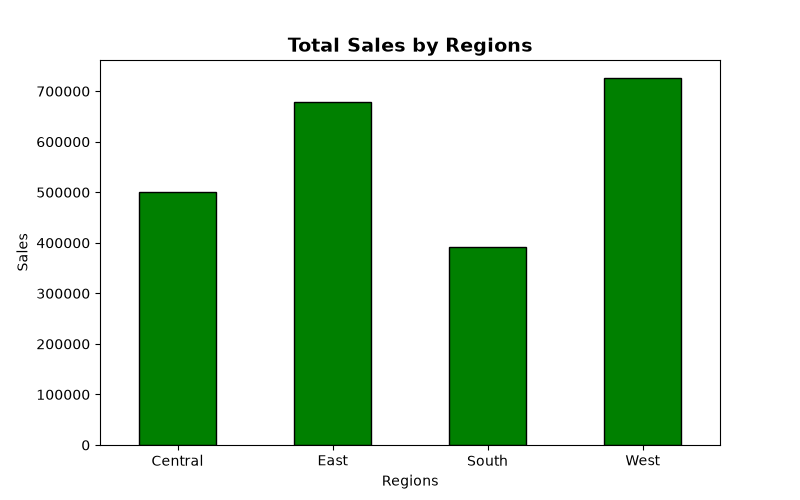

In [19]:
from IPython.display import Image, display

display(Image(filename="Images/regional_sales.png"))

### 6.2 Regional Profit Analysis

This section compares total profit across regions to identify the most profitable regions and areas that may require improvement.

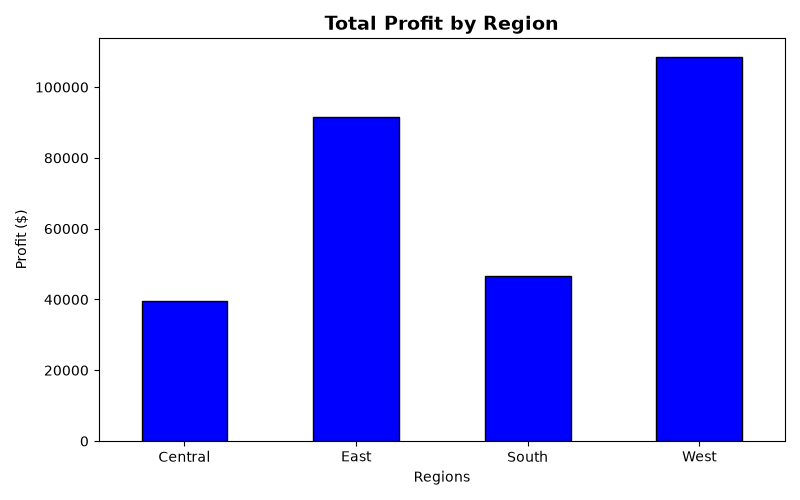

In [20]:
from IPython.display import Image, display

display(Image(filename="Images/regional_profit.png"))

### 6.3 Regional Sales vs Profit Analysis

This section compares total sales and profit across regions to evaluate regional business performance and identify differences between revenue generation and profitability.

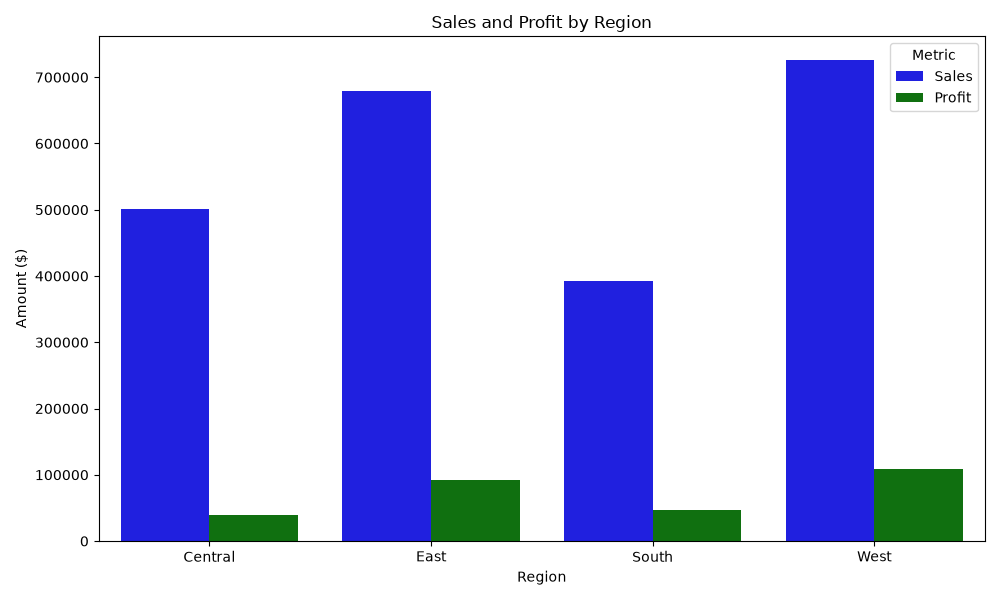

In [21]:
from IPython.display import Image, display

display(Image(filename="Images/regional_sales_profit.png"))

**Key Insights:**

- **West Region** leads in both sales and total profit, generating **$725,457.82 in sales** and **$108,418.45 in profit**.
- **East Region** ranks second in both metrics, with sales of **$678,781.24** and total profit of **$91,522.78**.
- **South Region** generates $391,721.91 in sales and $46,749.43 in profit, while the **Central Region** records $501,239.89 in sales and $39,706.36 in profit.
- Although Central generates more sales than South, its total profit is lower. This suggests that higher sales do not always translate into higher profit.
- West is the strongest region by total profit, whereas Central has the lowest total profit among the four regions.

**Recommendations:**

- Study the West Region's sales and product mix to identify practices that may be useful in other regions.
- Investigate why Central generates less profit than South despite having higher sales, examining discounts, product mix, and order-level profitability.
- Evaluate both total profit and profit margin before making regional business decisions.

## 7. State-wise Profitability Analysis

This section identifies the five most profitable and five least profitable states based on total profit.

### 7.1 Top 5 and Bottom 5 States — Combined Chart

The combined chart compares the highest-profit and lowest-profit states, highlighting differences in state-level profitability.

In [22]:
state_profit = (
    df.groupby("State")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

top5_profit = state_profit.head(5)
bottom5_profit = state_profit.tail(5)

print("Top 5 Most Profitable States:")
display(top5_profit)

print("\nBottom 5 Least Profitable States:")
display(bottom5_profit)

Top 5 Most Profitable States:


State
California    76381.3871
New York      74038.5486
Washington    33402.6517
Michigan      24463.1876
Virginia      18597.9504
Name: Profit, dtype: float64


Bottom 5 Least Profitable States:


State
North Carolina    -7490.9122
Illinois         -12607.8870
Pennsylvania     -15559.9603
Ohio             -16971.3766
Texas            -25729.3563
Name: Profit, dtype: float64

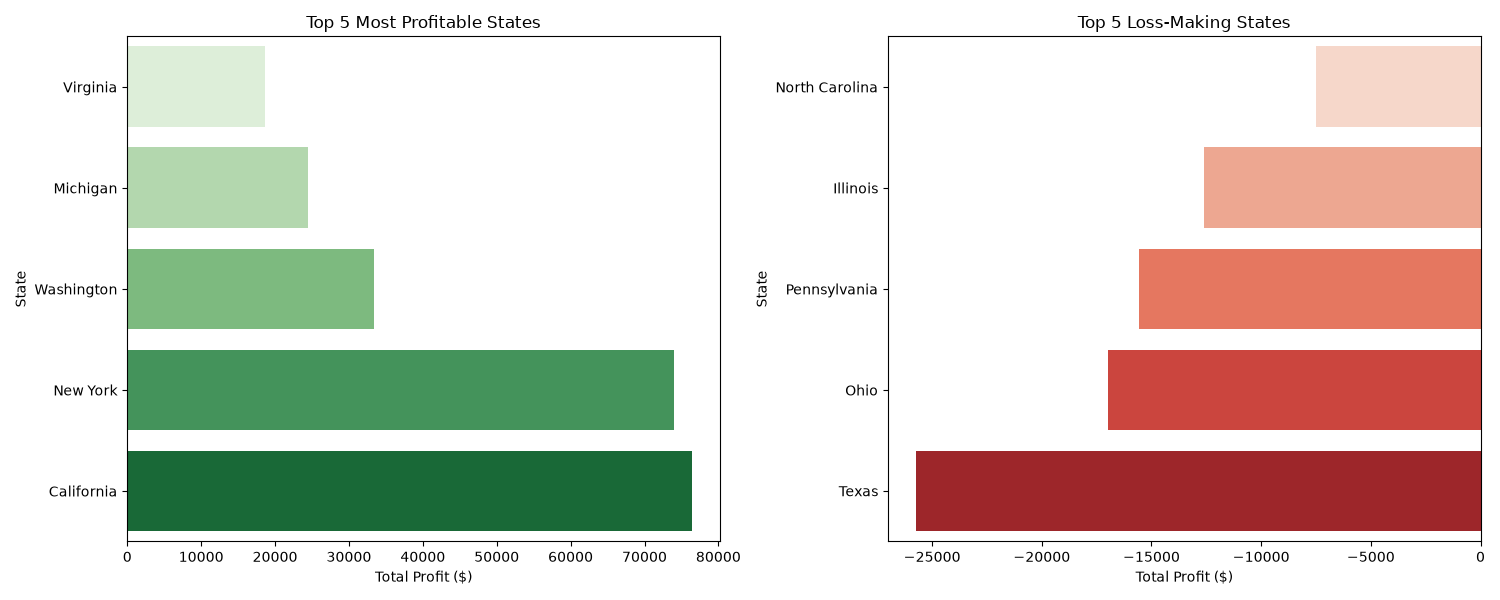

In [ ]:
from IPython.display import Image, display

display(Image(filename="Images/profitable_and_loss_making_states.png"))

**Key Insights:**

- **California** is the most profitable state, generating **$76,381.39** in total profit, followed by **New York** at **$74,038.55**.
- **Washington, Michigan, and Virginia** complete the top five most profitable states, with profits of $33,402.65, $24,463.19, and $18,597.95, respectively.
- **Texas** records the largest total loss at **−$25,729.36**, followed by Ohio (−$16,971.38) and Pennsylvania (−$15,559.96).
- **North Carolina** and **Illinois** also report negative total profits, at −$7,490.91 and −$12,607.89, respectively.
- These results show substantial differences in profitability across states. The business should investigate the factors behind losses in Texas, Ohio, and Pennsylvania, including discount levels, product mix, and sales performance.

**Recommendation:** Prioritize a detailed review of loss-making states, especially Texas, while studying the sales and product strategies associated with strong performance in California and New York.

## 8. Monthly Sales Trend Analysis

This section analyzes monthly sales over time to identify trends, fluctuations, and periods of higher or lower sales activity.

In [25]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

monthly_sales

Order Date
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


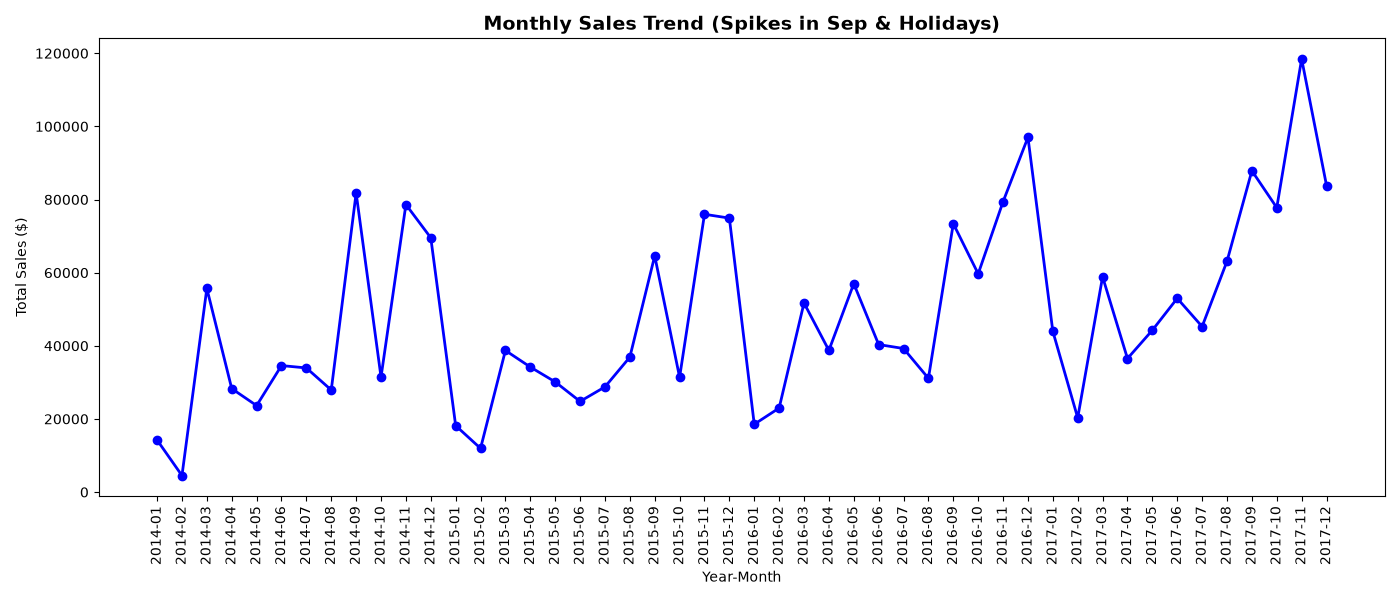

In [26]:
from IPython.display import Image, display

display(Image(filename="Images/monthly_sales_trend.png"))

**Key Insight:** Monthly sales fluctuate over time, indicating changes in sales activity across the year. Reviewing these trends can help the business plan inventory, marketing campaigns, and resource allocation more effectively.

## 9. Ship Mode-wise Profit Analysis

This section compares total profit across shipping methods to evaluate their contribution to overall business profitability.

In [27]:
shipmode_profit = (
    df.groupby("Ship Mode")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

shipmode_profit

Ship Mode
Standard Class    164088.7875
Second Class       57446.6354
First Class        48969.8399
Same Day           15891.7589
Name: Profit, dtype: float64

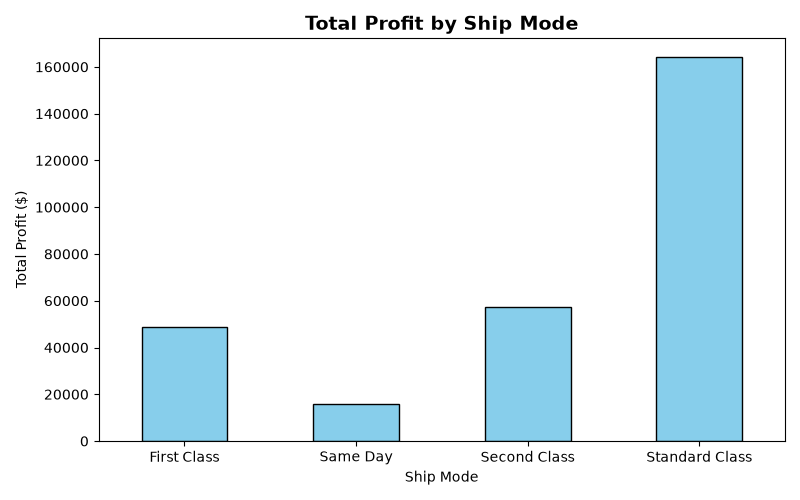

In [28]:
from IPython.display import Image, display

display(Image(filename="Images/ship_mode_profit.png"))

**Key Insight:** Standard Class generates the highest total profit among all shipping methods in the dataset. Comparing profit across ship modes helps the business understand which shipping options contribute most to overall profitability. However, higher total profit does not necessarily mean a shipping method is more profitable per order, since order volumes may differ.

## 10. Overall Business Insights and Recommendations

### Project Summary

This project analyzes the Superstore dataset using Python, Pandas, Matplotlib, and Seaborn to evaluate sales performance and profitability across product categories, sub-categories, discount levels, regions, states, and shipping methods. The analysis combines data aggregation, trend analysis, and visualizations to identify business strengths and potential areas for improvement.

### Key Business Findings

**1. Category-wise Profitability**

Technology generates the highest total profit, followed by Office Supplies, while Furniture contributes the least profit among the three categories. This highlights differences in profitability across product categories.

**2. Sub-Category Performance**

Tables and Bookcases generate negative total profit despite contributing to sales. These sub-categories require further investigation to understand the factors associated with their losses.

**3. Discount and Profit Relationship**

The analysis shows that higher discount levels are associated with lower average profit in this dataset. The business should review its discount strategy to identify which discount levels support sales without unnecessarily reducing profitability.

**4. Regional Performance**

The West Region leads in both total sales (**$725,457.82**) and total profit (**$108,418.45**), followed by the East Region. Although the Central Region generates more sales than the South Region, its total profit is lower, demonstrating that higher sales do not always translate into higher profit.

**5. State-wise Profitability**

California is the most profitable state, generating **$76,381.39**, followed by New York at **$74,038.55**. In contrast, Texas records the largest total loss at **−$25,729.36**, followed by Ohio and Pennsylvania. These states should be investigated further to identify potential profitability issues.

**6. Monthly Sales Trends**

Monthly sales fluctuate over time, providing useful information about changes in sales activity. These trends can support inventory planning, marketing decisions, and resource allocation.

**7. Shipping Method Performance**

Standard Class generates the highest total profit among the shipping methods. However, order volume and profit per order should also be examined before concluding that it is the most profitable shipping option on a per-order basis.

### Business Recommendations

- **Review loss-making products:** Investigate Tables and Bookcases to understand the effects of discounting, product costs, and sales performance.
- **Improve discount decisions:** Evaluate discount levels alongside profit margins and order-level performance before changing pricing policies.
- **Investigate underperforming states:** Prioritize Texas, Ohio, and Pennsylvania to identify opportunities to reduce losses.
- **Learn from stronger regions:** Examine the West and East Regions to identify successful product mixes and sales strategies that may be applicable elsewhere.
- **Monitor sales trends:** Use monthly sales patterns to improve inventory management and marketing plans.
- **Evaluate shipping profitability:** Compare shipping methods using order counts, average profit per order, and relevant shipping costs.

### Conclusion

The analysis demonstrates that sales volume alone is not a sufficient measure of business success. Product mix, discount levels, regional performance, and shipping methods all provide important perspectives on profitability. By investigating loss-making products and states, reviewing discount practices, and learning from stronger-performing regions, the business can make more informed, data-driven decisions.

This project demonstrates practical skills in data loading, aggregation, exploratory data analysis, trend analysis, and data visualization using Python.